# Chronological Policy Selection

## Selection Before Evaluation

Let $\Pi=\{\pi_1,\ldots,\pi_K\}$ be a fixed list of $K$ candidate policies. The selected policy is

$$
\widehat k
=\operatorname*{arg\,max}_{1\leq k\leq K}
\widehat V_{\mathrm{DR},\mathcal T}(\pi_k),
$$

where $\mathcal T$ contains only the earlier policy-selection dates. The final value is then calculated as $\widehat V_{\mathrm{DR},\mathcal H}(\pi_{\widehat k})$ on the later held-out dates $\mathcal H$. The final outcomes do not enter the maximization.

Row,Period,First date,Last date,Rows,Role
,String,String,String,Int64,String
1,Burn-in,2019-01-02,2019-10-16,200,Initial reward-model fitting only
2,Policy selection,2019-10-17,2022-06-29,680,Compare the five fixed candidates
3,Held-out evaluation,2022-06-30,2023-12-29,378,Evaluate the selected policy once


Row,Policy number,Policy,Training DR value,Selected
,Int64,String,Float64,String
1,0,Always defensive,0.000294981,Fail
2,1,Always cyclical,-0.0032452,Fail
3,2,Positive spread threshold,0.000483786,Fail
4,3,Smooth momentum,0.000272598,Fail
5,4,Volatility aware rule,0.000677229,Pass


Row,Policy number,Policy,Full-information value,IPW value,DR value,Selected earlier
,Int64,String,Float64,Float64,Float64,String
1,0,Always defensive,0.000134193,0.000425819,0.000336091,Fail
2,1,Always cyclical,0.00122956,0.00219942,0.00218732,Fail
3,2,Positive spread threshold,0.00095496,0.00115698,0.00118885,Fail
4,3,Smooth momentum,0.000966589,0.00127797,0.00127505,Fail
5,4,Volatility aware rule,0.000915362,0.00101196,0.00099393,Pass


Row,Quantity,Value
,String,Any
1,Selected policy number,4
2,Selected policy,Volatility aware rule
3,Selected training DR value,0.000677229
4,Held-out IPW value,0.00101196
5,Held-out DR value,0.00099393
6,Held-out effective sample size,345.419
7,Held-out maximum weight,1.48014


Row,Policy,Mean probability of action 1 in selection period,Mean probability of action 1 in held-out period
,String,Float64,Float64
1,Always defensive,0.0,0.0
2,Always cyclical,1.0,1.0
3,Positive spread threshold,0.727941,0.669312
4,Smooth momentum,0.652052,0.622982
5,Volatility aware rule,0.516325,0.523919


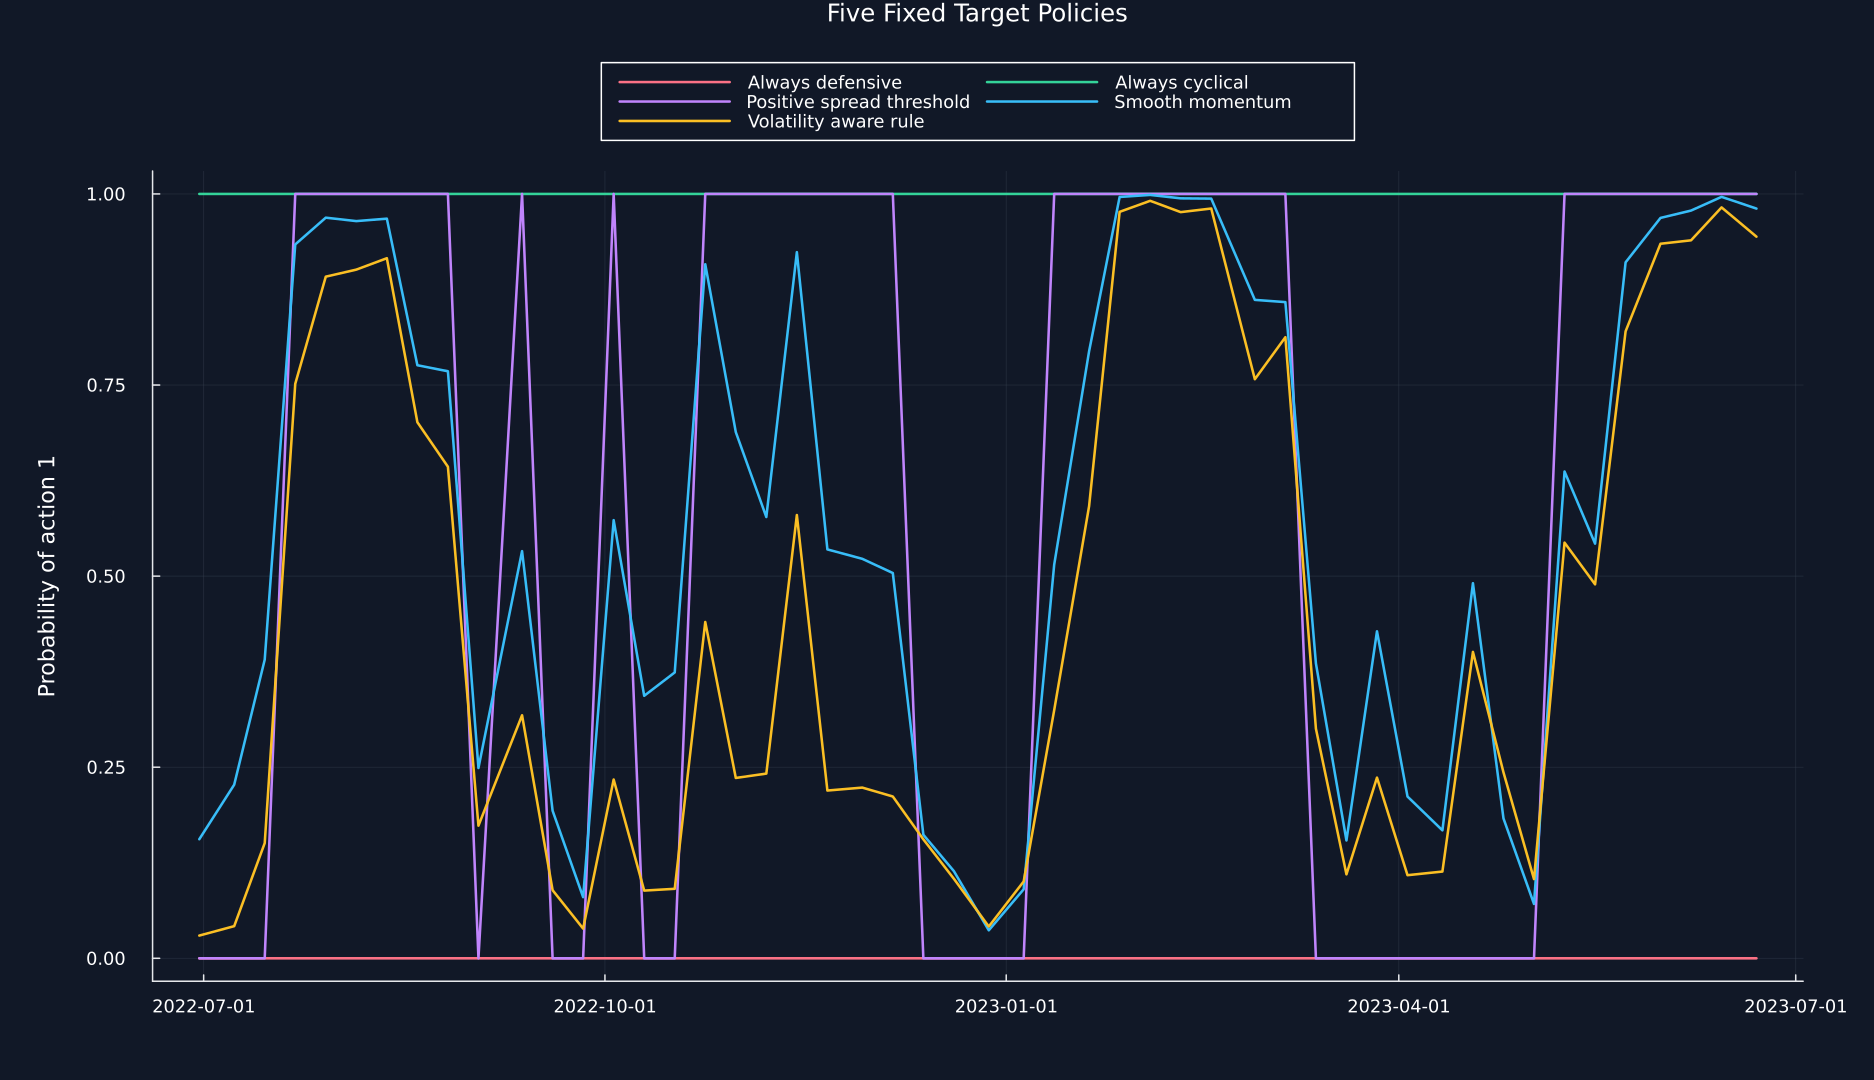

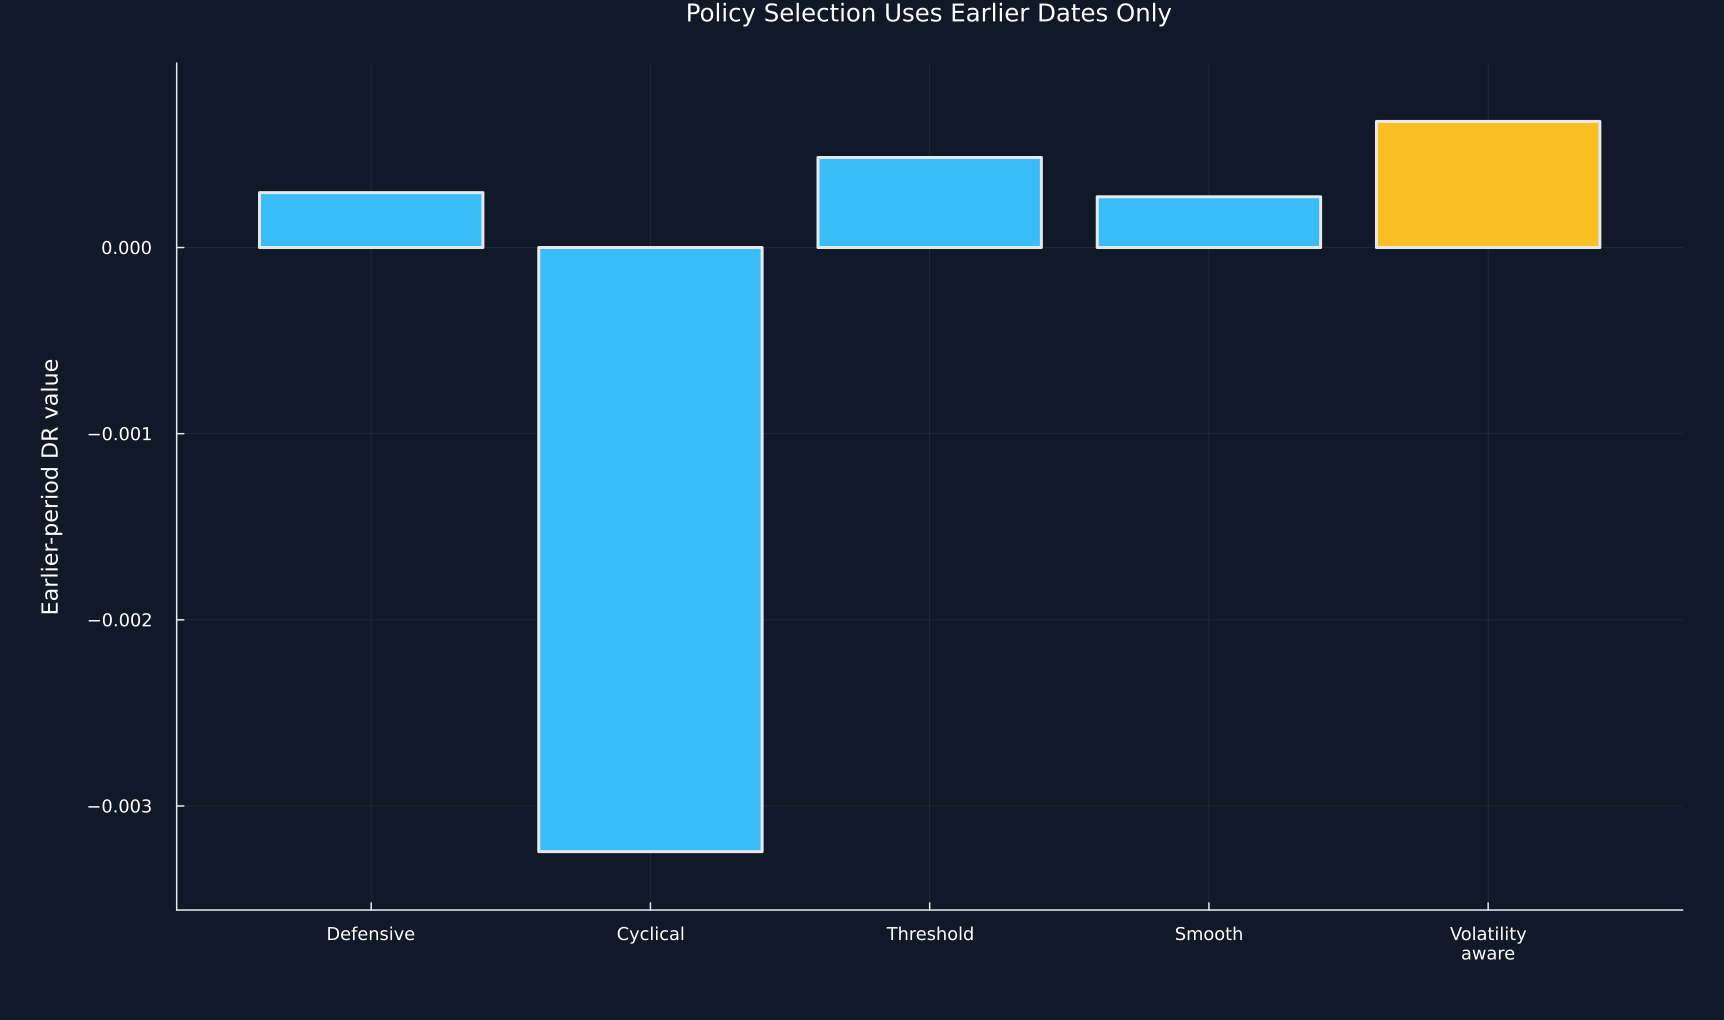

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("09_policy_evaluation");
using CSV,TOML,Printf
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
include(joinpath("..","support","BookIdentificationStudy.jl"))
using .BookIdentificationStudy: PrimitiveStore,normal_block
include(joinpath("..","support","BookPolicyStudy.jl"))
using .BookPolicyStudy
default(left_margin=10Plots.mm,bottom_margin=10Plots.mm)
store=PrimitiveStore(joinpath("..","data","chapter09_random_inputs"),"policy")
captions=Dict("ipw_data_provenance"=>"Provenance of the public returns used in the policy illustration.","ipw_basket_definitions"=>"Fixed public basket definitions.","ipw_sample_contract"=>"Data and decision contract for the illustration.","ipw_context_summary"=>"Summary of the past-only context variables.","ipw_behavior_summary"=>"Summary of the generated behavior policy and realized actions.","ipw_candidate_definitions"=>"Five fixed target policies.","ipw_policy_values"=>"Public full-information values and inverse probability estimates.","ipw_weight_summary"=>"Importance-weight diagnostics for the five target policies.","ipw_manual_score_rows"=>"First eight contributions for the smooth momentum policy.","ipw_support_checks"=>"Overlap and probability checks for the main target policy.","ipw_overlap_sensitivity"=>"Sensitivity of the smooth momentum estimate to the behavior probability floor.","ipw_invalid_support_checks"=>"Required rejections for invalid probability support.","ipw_section_summary"=>"Summary of the inverse probability illustration.","dr_exact_cases"=>"Exact four-row double robustness check.","dr_exact_scores"=>"Row contributions in the exact double robustness check.","dr_fold_plan"=>"Chronological reward-prediction folds.","dr_oof_checks"=>"Information-boundary checks for reward predictions.","dr_prediction_quality"=>"Quality of chronological reward predictions against both public basket returns.","dr_oof_sample_rows"=>"Selected chronological reward predictions from the policy-selection period.","dr_policy_comparison"=>"Held-out full-information, inverse probability, and doubly robust values.","dr_score_summary"=>"Held-out score distributions for the smooth momentum policy.","dr_nuisance_scenarios"=>"Algebraic nuisance-input diagnostics for the smooth momentum policy.","dr_invalid_input_checks"=>"Required rejections for incompatible policy-evaluation inputs.","dr_section_summary"=>"Summary of the doubly robust evaluation.","selection_split"=>"Chronological split used for policy selection and evaluation.","selection_training_values"=>"Earlier-period doubly robust values used for selection.","selection_heldout_values"=>"Held-out values shown after the earlier policy choice.","selection_result"=>"Result of chronological selection followed by held-out evaluation.","selection_policy_action_shares"=>"Average action-one probabilities of the fixed candidates.","selection_outcome_isolation"=>"Selection is unchanged when only held-out outcomes are replaced.","selection_tie_rule"=>"First-candidate rule for exactly equal training values.","selection_invalid_checks"=>"Required rejections for invalid chronological splits.","selection_final_diagnostics"=>"Diagnostics for the policy chosen on earlier dates.","selection_section_summary"=>"Summary of chronological policy selection.")
function table(values,name)
    shown=copy(values)
    for column in names(shown)
        if all(value->value isa Bool,shown[!,column])
            shown[!,column]=ifelse.(shown[!,column],"Pass","Fail")
        end
    end
    save_table(shown,paths,name;caption=captions[name],label="tab:cim9-"*replace(name,"_"=>"-"))
    return nothing
end
panel=build_policy_frame(store)
policy_names,candidates=candidate_policies(panel)
behavior=behavior_matrix(panel)
potential=potential_matrix(panel)
actions=panel.Action
rewards=panel[:,"Observed reward"]
predictions,fold_plan,fold_coefficients=chronological_predictions(panel)
training=collect(201:880)
heldout=collect(881:nrow(panel))
selection=policy_selection(actions,rewards,behavior,candidates,predictions;training_indices=training,evaluation_indices=heldout)
selected=selection.selected_policy
selected_number=selected-1
split_table=frame(["Period","First date","Last date","Rows","Role"],[("Burn-in",string(panel.Date[1]),string(panel.Date[200]),200,"Initial reward-model fitting only"),("Policy selection",string(panel.Date[first(training)]),string(panel.Date[last(training)]),length(training),"Compare the five fixed candidates"),("Held-out evaluation",string(panel.Date[first(heldout)]),string(panel.Date[last(heldout)]),length(heldout),"Evaluate the selected policy once")])
table(split_table,"selection_split")
training_values=DataFrame("Policy number"=>collect(0:4),"Policy"=>policy_names,"Training DR value"=>selection.training_values,"Selected"=>collect(1:5).==selected)
table(training_values,"selection_training_values")
heldout_rows=[]
training_score_rows=[]
for (index,name) in enumerate(policy_names)
    policy=candidates[index,:,:]
    result=policy_evaluation(actions[heldout],rewards[heldout],behavior[heldout,:],policy[heldout,:],predictions[heldout,:])
    push!(heldout_rows,(index-1,name,full_information_value(panel,policy,heldout),result.ipw_value,result.dr_value,index==selected))
    earlier=policy_evaluation(actions[training],rewards[training],behavior[training,:],policy[training,:],predictions[training,:])
    for (position,row) in enumerate(training)
        push!(training_score_rows,(index-1,panel.Date[row],earlier.importance_weights[position],earlier.ipw_scores[position],earlier.dr_scores[position]))
    end
end
heldout_values=frame(["Policy number","Policy","Full-information value","IPW value","DR value","Selected earlier"],heldout_rows)
table(heldout_values,"selection_heldout_values")
save_data(frame(["Policy number","Date","Importance weight","IPW score","DR score"],training_score_rows),paths,"policy_all_training_scores")
selection_result=frame(["Quantity","Value"],[("Selected policy number",selected_number),("Selected policy",policy_names[selected]),("Selected training DR value",selection.training_values[selected]),("Held-out IPW value",selection.evaluation.ipw_value),("Held-out DR value",selection.evaluation.dr_value),("Held-out effective sample size",selection.evaluation.effective_sample_size),("Held-out maximum weight",selection.evaluation.max_weight)])
table(selection_result,"selection_result")
action_shares=frame(["Policy","Mean probability of action 1 in selection period","Mean probability of action 1 in held-out period"],[(name,mean(candidates[index,training,2]),mean(candidates[index,heldout,2])) for (index,name) in enumerate(policy_names)])
table(action_shares,"selection_policy_action_shares")
probability_rows=collect(881:5:min(1130,nrow(panel)))
probability_plot=DataFrame("Date"=>panel.Date[probability_rows])
colors=[palette.rose,palette.green,violet,palette.cyan,palette.amber]
figure=plot(;ylims=(-.03,1.03),ylabel="Probability of action 1",title="Five Fixed Target Policies",size=(1250,720),legend=:outertop,legend_columns=2)
for (index,name) in enumerate(policy_names)
    probability_plot[!,name]=candidates[index,probability_rows,2]
    plot!(figure,probability_plot.Date,probability_plot[:,name];color=colors[index],linewidth=1.7,label=name)
end
save_data(probability_plot,paths,"selection_candidate_probabilities")
plot!(figure;right_margin=10Plots.mm)
save_figure(figure,paths,"selection_candidate_probabilities")
save_data(training_values,paths,"selection_training_values")
figure=bar(1:5,training_values[:,3];color=ifelse.(training_values.Selected,palette.amber,palette.cyan),label="",xticks=(1:5,["Defensive","Cyclical","Threshold","Smooth","Volatility\naware"]),ylabel="Earlier-period DR value",title="Policy Selection Uses Earlier Dates Only",size=(1150,680))
bar_headroom!(figure,training_values[:,3])
save_figure(figure,paths,"selection_training_values")


## Protecting the outcome period under deterministic tie rules

The selection calculation is a function of earlier data only. If two copies of the calculation have identical earlier data but different final outcomes, they must return the same selected policy. This is checked directly below.

When candidates have exactly equal earlier values, the declared rule selects the first candidate. This deterministic rule makes the result reproducible; it does not claim that the first policy is scientifically better.

Row,Final outcome pattern,Selected policy number,Selected policy,Held-out DR value
,String,Int64,String,Float64
1,Large positive values,4,Volatility aware rule,0.20673
2,Large negative values,4,Volatility aware rule,-0.206766


Row,Candidate,Training DR value,Selected
,Int64,Float64,String
1,0,0.000272598,Pass
2,1,0.000272598,Fail


Row,Check,Rejected,Explanation
,String,String,String
1,Training dates interleaved with evaluation dates,Pass,Stopped as required
2,Repeated training index,Pass,Stopped as required
3,Training and evaluation overlap,Pass,Stopped as required
4,Empty evaluation period,Pass,Stopped as required


Row,Quantity,Value
,String,Real
1,Held-out full-information value,0.000915362
2,Held-out IPW value,0.00101196
3,Held-out DR value,0.00099393
4,IPW absolute error,9.65955e-5
5,DR absolute error,7.85684e-5
6,Held-out dates,378


Row,Result,Value
,String,String
1,Candidate list,Fixed before held-out evaluation
2,Selection information,Earlier-period doubly robust values only
3,Held-out information,Used once to evaluate the selected policy
4,Outcome-isolation check,Changing final outcomes does not change selection
5,Tie rule,First candidate wins an exact tie


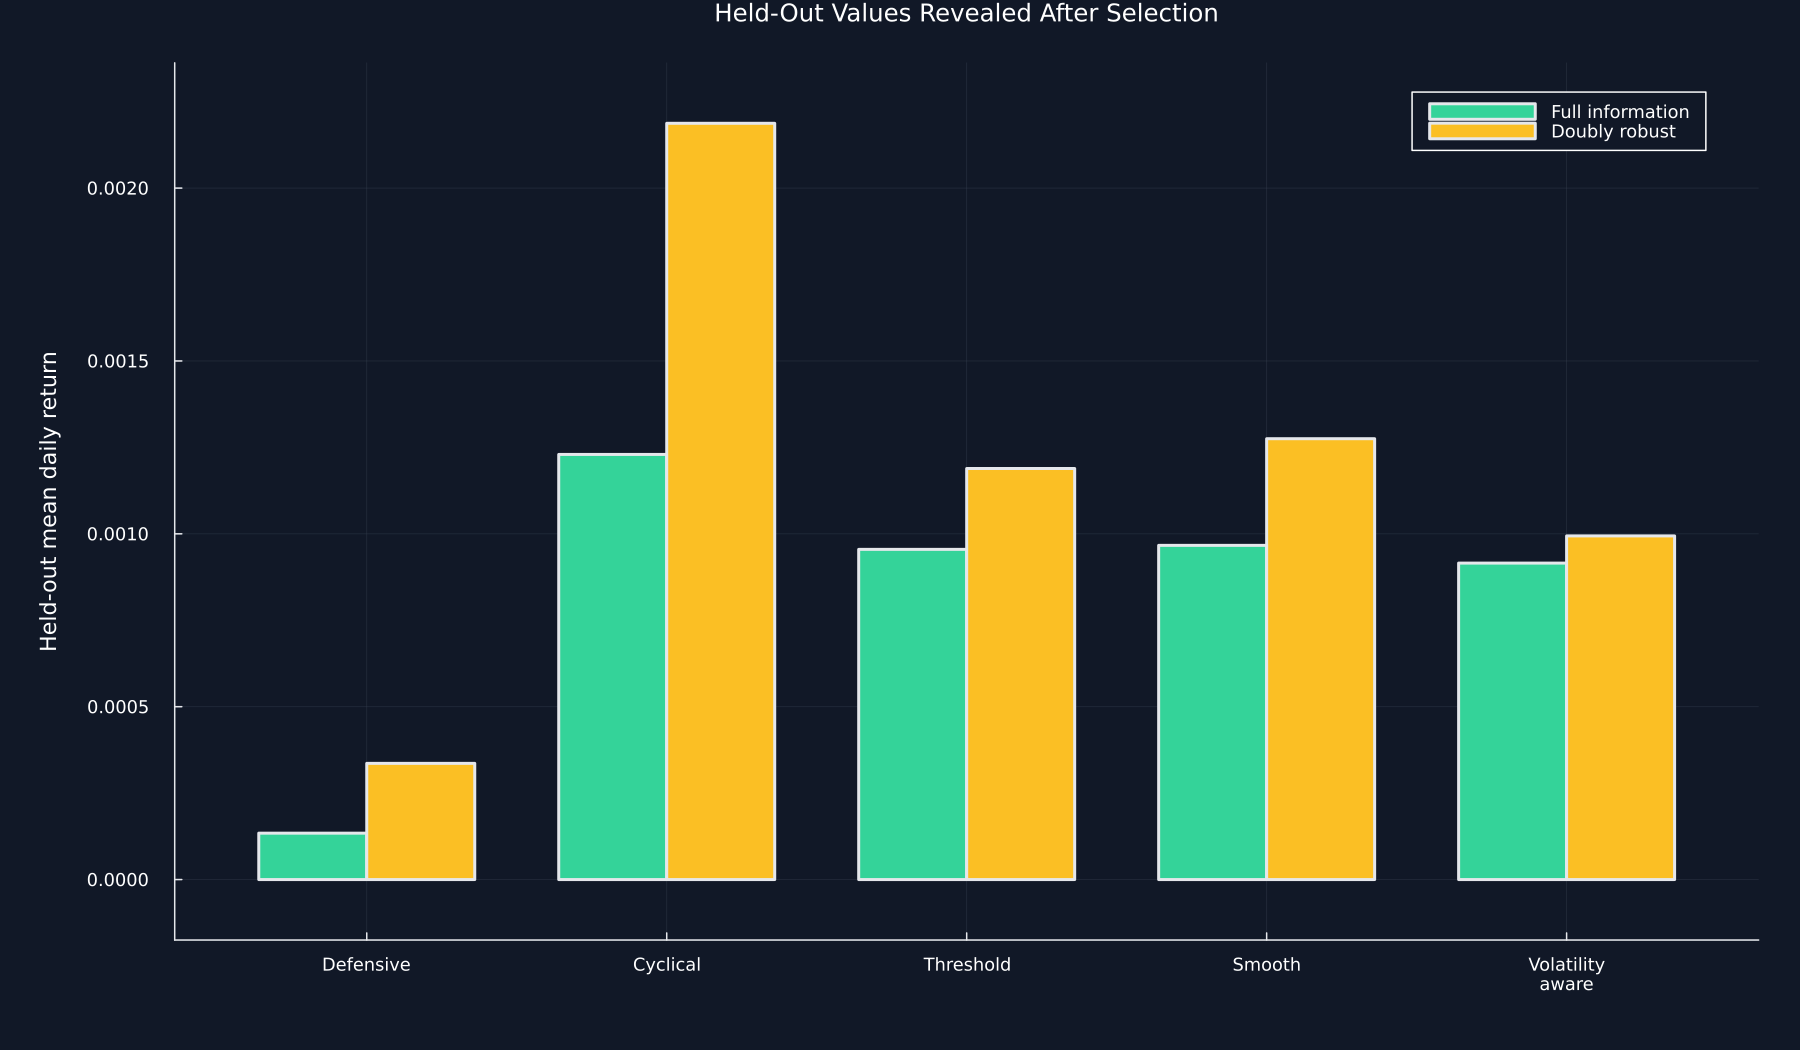

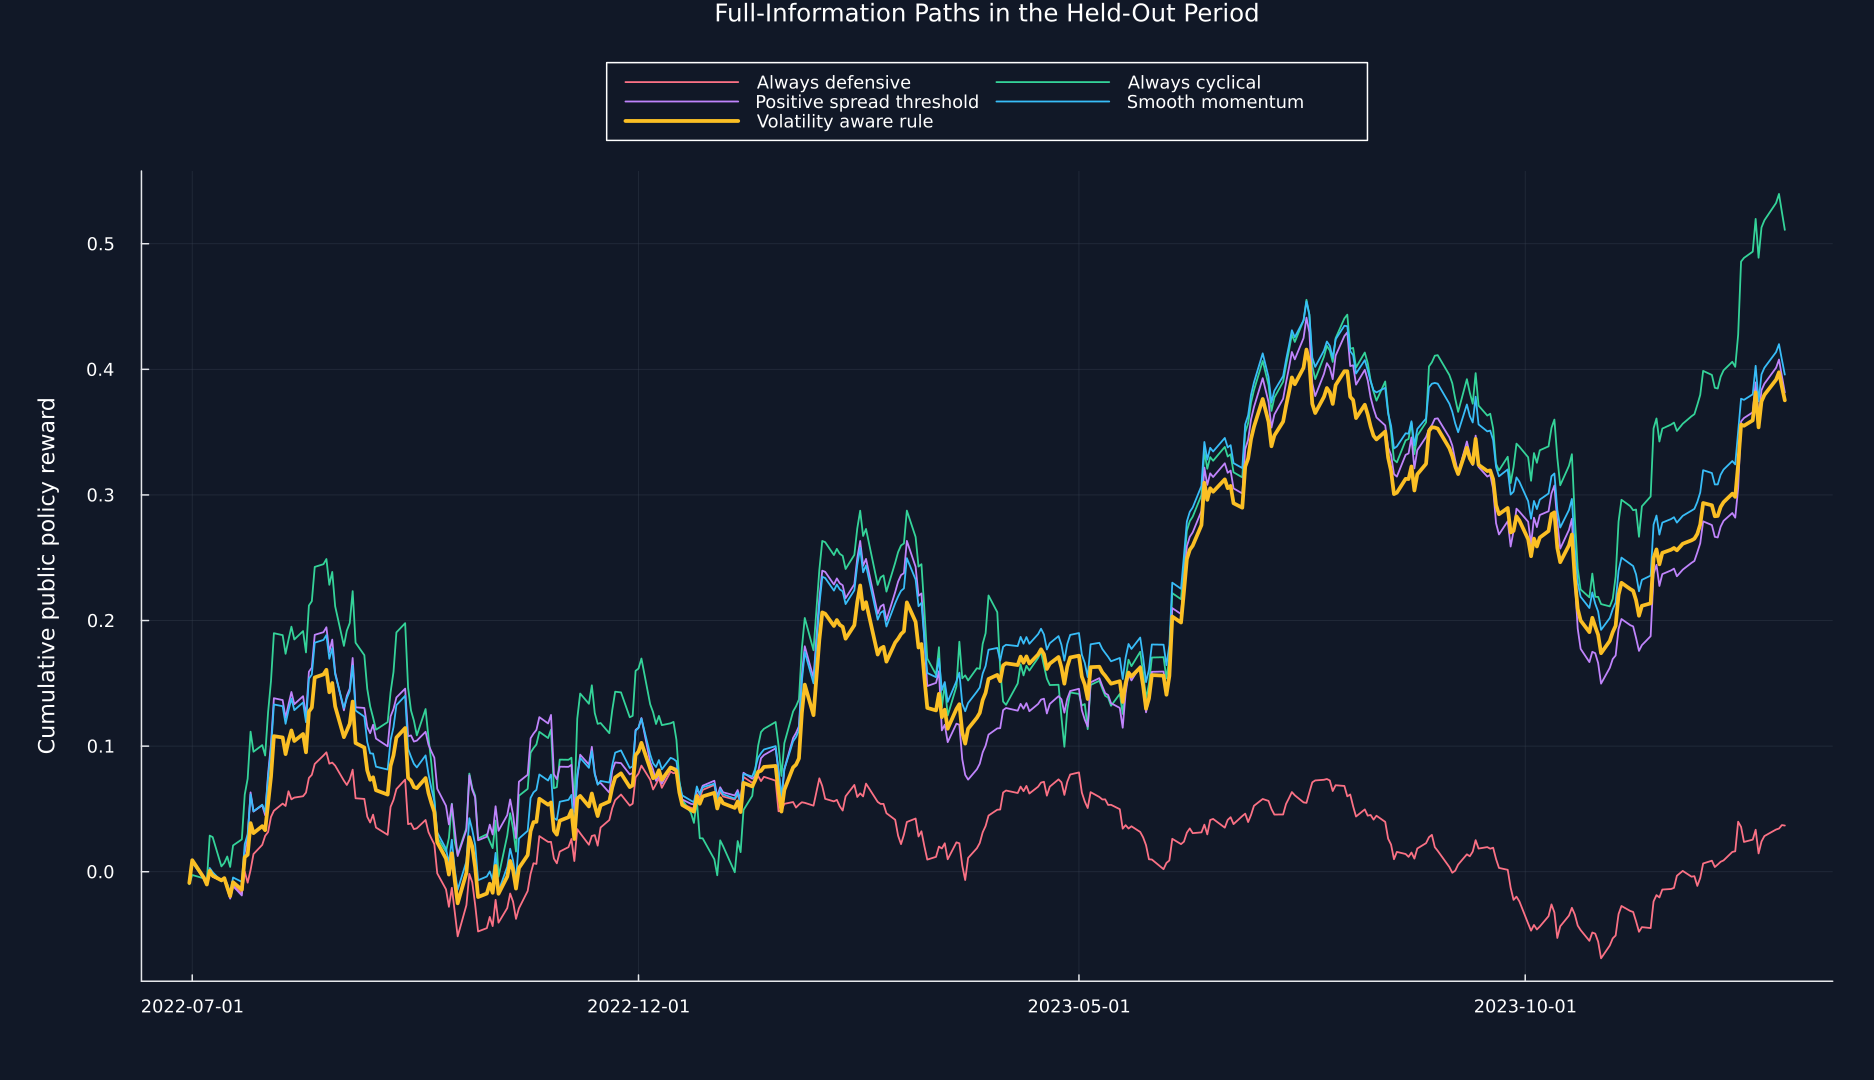

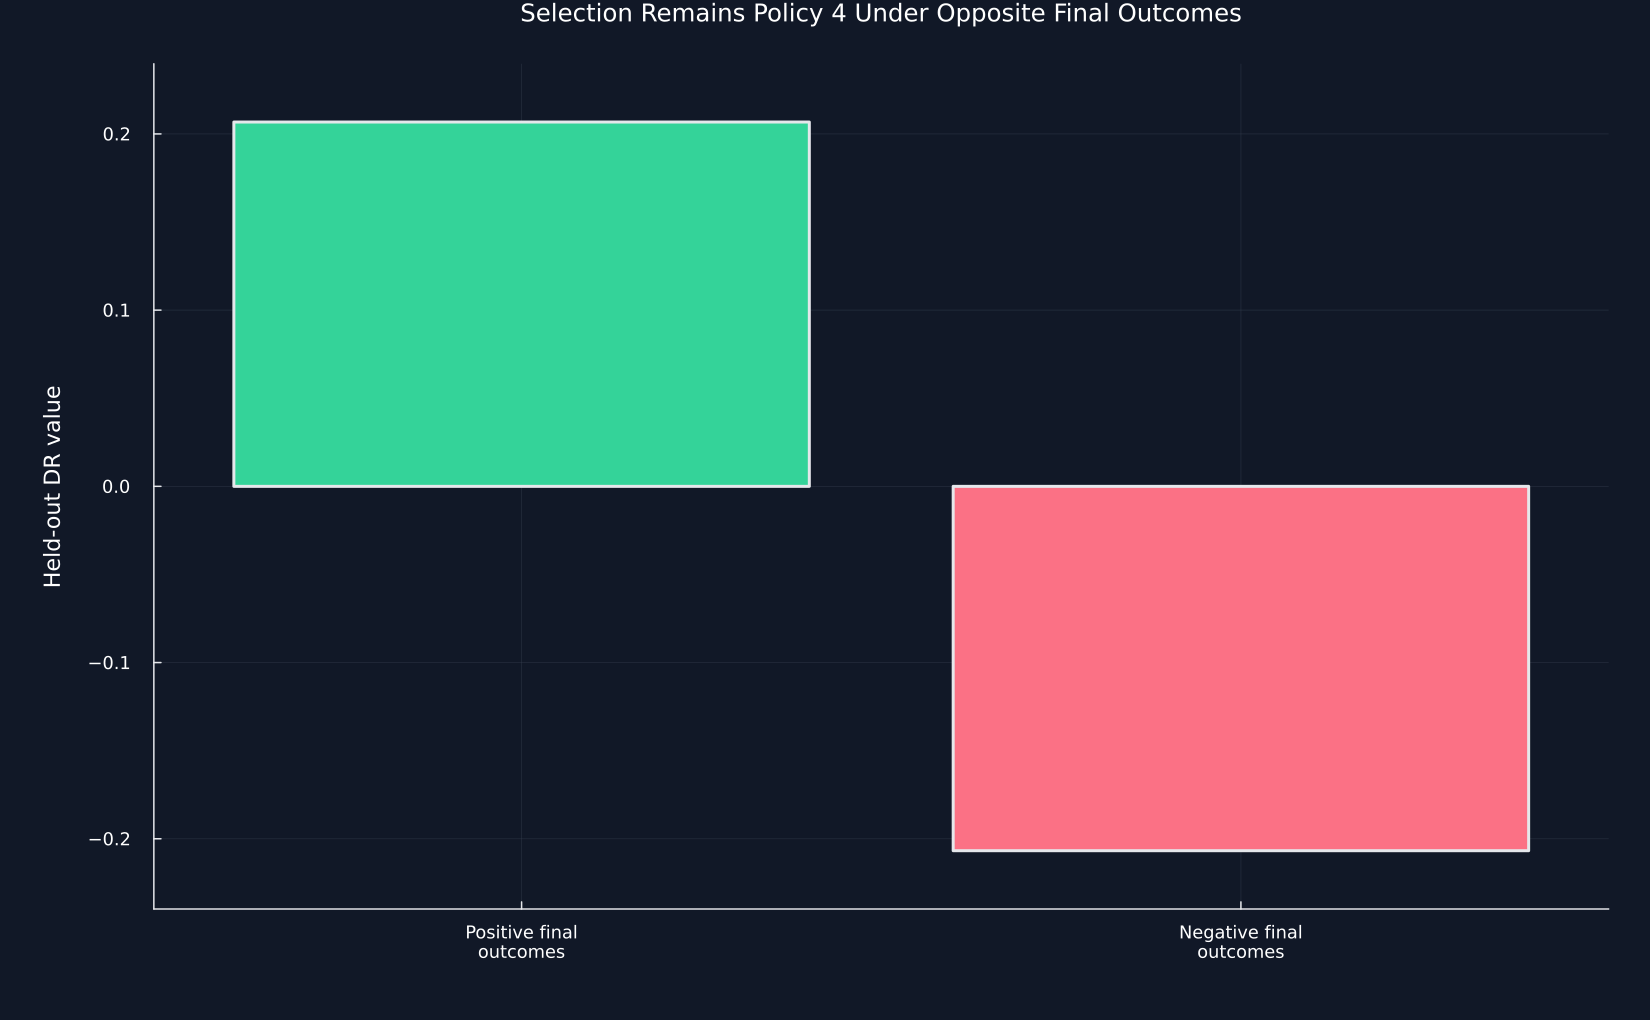

In [2]:
rewards_high=copy(rewards)
rewards_low=copy(rewards)
rewards_high[heldout]= .20 .+abs.(rewards_high[heldout])
rewards_low[heldout]= -.20 .-abs.(rewards_low[heldout])
high_result=policy_selection(actions,rewards_high,behavior,candidates,predictions;training_indices=training,evaluation_indices=heldout)
low_result=policy_selection(actions,rewards_low,behavior,candidates,predictions;training_indices=training,evaluation_indices=heldout)
outcome_isolation=frame(["Final outcome pattern","Selected policy number","Selected policy","Held-out DR value"],[("Large positive values",high_result.selected_policy-1,policy_names[high_result.selected_policy],high_result.evaluation.dr_value),("Large negative values",low_result.selected_policy-1,policy_names[low_result.selected_policy],low_result.evaluation.dr_value)])
table(outcome_isolation,"selection_outcome_isolation")
duplicates=candidates[[4,4],:,:]
tie_result=policy_selection(actions,rewards,behavior,duplicates,predictions;training_indices=training,evaluation_indices=heldout)
tie_rule=DataFrame("Candidate"=>[0,1],"Training DR value"=>tie_result.training_values,"Selected"=>[tie_result.selected_policy==1,tie_result.selected_policy==2])
table(tie_rule,"selection_tie_rule")
invalid_checks=frame(["Check","Rejected","Explanation"],[capture_failure("Training dates interleaved with evaluation dates",()->policy_selection(actions,rewards,behavior,candidates,predictions;training_indices=[201,901],evaluation_indices=[881,1001])),capture_failure("Repeated training index",()->policy_selection(actions,rewards,behavior,candidates,predictions;training_indices=[201,201,202],evaluation_indices=heldout)),capture_failure("Training and evaluation overlap",()->policy_selection(actions,rewards,behavior,candidates,predictions;training_indices=collect(201:900),evaluation_indices=heldout)),capture_failure("Empty evaluation period",()->policy_selection(actions,rewards,behavior,candidates,predictions;training_indices=training,evaluation_indices=Int[]))])
table(invalid_checks,"selection_invalid_checks")
selected_policy=candidates[selected,:,:]
selected_full=full_information_value(panel,selected_policy,heldout)
diagnostics=frame(["Quantity","Value"],[("Held-out full-information value",selected_full),("Held-out IPW value",selection.evaluation.ipw_value),("Held-out DR value",selection.evaluation.dr_value),("IPW absolute error",abs(selection.evaluation.ipw_value-selected_full)),("DR absolute error",abs(selection.evaluation.dr_value-selected_full)),("Held-out dates",length(heldout))])
table(diagnostics,"selection_final_diagnostics")
section_summary = frame(["Result","Value"],[["Candidate list","Fixed before held-out evaluation"],["Selection information","Earlier-period doubly robust values only"],["Held-out information","Used once to evaluate the selected policy"],["Outcome-isolation check","Changing final outcomes does not change selection"],["Tie rule","First candidate wins an exact tie"]])
table(section_summary,"selection_section_summary")
save_data(heldout_values,paths,"selection_heldout_values")
positions=collect(1:5)
figure=bar(positions.-.18,heldout_values[:,3];bar_width=.36,color=palette.green,label="Full information",xticks=(positions,["Defensive","Cyclical","Threshold","Smooth","Volatility\naware"]),ylabel="Held-out mean daily return",title="Held-Out Values Revealed After Selection",size=(1200,700))
bar!(figure,positions.+.18,heldout_values[:,5];bar_width=.36,color=palette.amber,label="Doubly robust")
bar_headroom!(figure,Matrix(heldout_values[:,[3,5]]))
save_figure(figure,paths,"selection_heldout_values")
cumulative=DataFrame("Date"=>panel.Date[heldout])
figure=plot(;ylabel="Cumulative public policy reward",title="Full-Information Paths in the Held-Out Period",size=(1250,720),legend=:outertop,legend_columns=2)
for (index,name) in enumerate(policy_names)
    daily=vec(sum(candidates[index,heldout,:].*potential[heldout,:];dims=2))
    cumulative[!,name]=cumprod(1 .+daily).-1
    plot!(figure,cumulative.Date,cumulative[:,name];color=colors[index],linewidth=index==selected ? 2.5 : 1.2,label=name)
end
save_data(cumulative,paths,"selection_cumulative_rewards")
save_figure(figure,paths,"selection_cumulative_rewards")
save_data(outcome_isolation,paths,"selection_outcome_isolation")
figure=bar(1:2,outcome_isolation[:,4];color=[palette.green,palette.rose],label="",xticks=(1:2,["Positive final\noutcomes","Negative final\noutcomes"]),ylabel="Held-out DR value",title="Selection Remains Policy "*string(selected_number)*" Under Opposite Final Outcomes",size=(1100,680))
bar_headroom!(figure,outcome_isolation[:,4])
save_figure(figure,paths,"selection_outcome_isolation")
